# 7. Estimators and maximum likelihood

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 4 and 5, some calculus

**Reading:** Taylor, ch. 5.5 and 7 · Bevington & Robinson, ch. 4.1 and 10 ·
Fornasini, ch. 7.3 · Rouaud, ch. IV · Cowan, *Statistical Data Analysis*,
ch. 5 and 6

Every number extracted from data, a mean, a standard deviation, a slope, is
an **estimator**: a recipe that turns data into a value for an unknown
quantity. Different recipes can be applied to the same data and give
different answers, so we need criteria for judging them, and a general
method for constructing good ones. This chapter provides both.

1. Bias, variance and mean-square error measure the quality of an
   estimator; the familiar $N-1$ is a bias correction, and $s$ is still
   biased.
2. Two estimators of the same quantity can differ enormously in precision.
3. The method of maximum likelihood constructs estimators systematically.
   It justifies the mean, the weighted mean and least squares.
4. The likelihood also supplies the uncertainty: from its curvature, or,
   better for small samples, from the interval where it falls by a fixed
   amount.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(107)

## 7.1 Bias, variance and mean-square error

An estimator $\hat\theta$ computed from random data is itself a random
variable, with a distribution over imagined repetitions of the experiment.
Its quality is described by

* the **bias** $b = \langle\hat\theta\rangle - \theta$, a systematic error of
  the method;
* the **variance** $\operatorname{var}(\hat\theta)$, its statistical
  uncertainty;
* the **mean-square error**
  $\mathrm{MSE} = \langle(\hat\theta - \theta)^2\rangle = \operatorname{var}(\hat\theta) + b^2$,
  which combines the two.

An estimator is **consistent** if it converges to $\theta$ as the amount of
data grows; the bias and the variance both vanish.

**The variance and the standard deviation.** For $N$ readings with mean
$\mu$ and variance $\sigma^2$,

$$ \Bigl\langle\sum_i (x_i - \bar x)^2\Bigr\rangle = (N-1)\,\sigma^2 , $$

because $\sum (x_i - \bar x)^2 = \sum (x_i - \mu)^2 - N(\bar x - \mu)^2$ and
the last term has expectation $N\cdot\sigma^2/N = \sigma^2$. Dividing by
$N-1$ makes $s^2$ an unbiased estimator of $\sigma^2$. Its square root is
*not* unbiased for $\sigma$, because the square root is concave: for
normal data $\langle s\rangle = c_4(N)\,\sigma$, with

$$ c_4(N) = \sqrt{\frac{2}{N-1}}\;\frac{\Gamma(N/2)}{\Gamma\bigl((N-1)/2\bigr)} \approx 1 - \frac{1}{4N} . $$

One teaching guide suggests dividing by $N - 1.5$ instead of $N - 1$ for
small samples. This approximates the same correction well from about five
readings upwards, less well for two or three.

In [2]:
def c4(N):
    return np.sqrt(2 / (N - 1)) * np.exp(special.gammaln(N / 2) - special.gammaln((N - 1) / 2))

print("  N    <s>/sigma (simulated)   c4(N)   implied by dividing by N - 1.5")
for N in (2, 3, 5, 10, 30):
    s = rng.normal(0, 1, (200_000, N)).std(axis=1, ddof=1)
    print(f"{N:3d}          {s.mean():.4f}           {c4(N):.4f}       {np.sqrt((N - 1.5) / (N - 1)):.4f}")

  N    <s>/sigma (simulated)   c4(N)   implied by dividing by N - 1.5
  2          0.7968           0.7979       0.7071
  3          0.8860           0.8862       0.8660
  5          0.9396           0.9400       0.9354
 10          0.9723           0.9727       0.9718


 30          0.9917           0.9914       0.9913


The bias of $s$ is a few per cent for five readings, much smaller than its
statistical uncertainty ($\approx 35\,\%$, Section 4.3); for that reason it is
usually ignored. It matters when many small samples are pooled, as in
control charts, where $\bar s/c_4$ is the standard estimate.

**Dividing by $N$ or by $N-1$?** The estimator with $N$ is biased low, but
it has a smaller variance. For normal data, the mean-square error of
$\hat\sigma^2$ is actually smallest when one divides by $N+1$. "Unbiased"
is a reasonable default, not a law: what matters in the end is how far the
estimate is likely to be from the truth.

In [3]:
N, sigma2 = 5, 1.0
x = rng.normal(0, 1, (400_000, N))
ss = ((x - x.mean(axis=1, keepdims=True))**2).sum(axis=1)
print("divisor   bias of the variance estimate    root-mean-square error")
for d in (N - 1, N, N + 1):
    v = ss / d
    print(f"  {d}             {v.mean() - sigma2:+.4f}                      {np.sqrt(np.mean((v - sigma2)**2)):.4f}")

divisor   bias of the variance estimate    root-mean-square error
  4             +0.0006                      0.7091
  5             -0.1995                      0.6014
  6             -0.3329                      0.5782


## 7.2 Not all estimators are equally good

**Mean or median?** Both estimate the centre of a symmetric distribution.
For normal data the median scatters more: its variance is larger by the
factor $\pi/2 \approx 1.57$ for large $N$, so the median "wastes" a third of
the data. For distributions with heavier tails the comparison reverses
(Chapter 9).

**A striking case: the width of a uniform distribution.** Readings are
known to be uniformly distributed between 0 and an unknown upper limit
$a$; examples are the phase of an unsynchronised signal or a position
known only to lie on a segment. The *method of moments* matches the sample
mean to the distribution mean $a/2$, giving $\hat a_\text{MM} = 2\bar x$. A
second estimator uses the largest reading, corrected for its bias,
$\hat a_\text{max} = \tfrac{N+1}{N}\max_i x_i$. Both are unbiased.

In [4]:
a_true = 1.0
print("  N    std of 2*mean     std of (N+1)/N*max    ratio")
Ns = np.array([2, 5, 10, 20, 50, 100, 200])
sd_mm, sd_max = [], []
for N in Ns:
    x = rng.uniform(0, a_true, (100_000, N))
    a_mm = 2 * x.mean(axis=1)
    a_mx = (N + 1) / N * x.max(axis=1)
    sd_mm.append(a_mm.std()); sd_max.append(a_mx.std())
    print(f"{N:4d}      {a_mm.std():.4f}            {a_mx.std():.4f}          {a_mm.std() / a_mx.std():5.1f}")

  N    std of 2*mean     std of (N+1)/N*max    ratio
   2      0.4079            0.3528            1.2
   5      0.2583            0.1691            1.5
  10      0.1828            0.0910            2.0
  20      0.1291            0.0476            2.7
  50      0.0817            0.0196            4.2


 100      0.0578            0.0099            5.9


 200      0.0409            0.0050            8.2


The uncertainty of $2\bar x$ falls as $1/\sqrt N$, that of the corrected
maximum as $1/N$. With 100 readings the second is six times more precise,
equivalent to having 36 times as much data. The reason is that the largest
reading carries almost all the information about the upper edge; the mean
dilutes it with readings that say nothing about where the edge is. The
recipe that seems natural is not always the efficient one, and a
systematic method is needed.

## 7.3 The principle of maximum likelihood

Suppose the readings $x_1, \dots, x_N$ are independent with a probability
density $p(x;\theta)$ that depends on an unknown parameter $\theta$. The
probability (density) of obtaining the observed data, regarded as a
function of $\theta$, is the **likelihood**

$$ L(\theta) = \prod_{i=1}^{N} p(x_i;\theta), \qquad
   \ln L(\theta) = \sum_{i=1}^{N} \ln p(x_i;\theta) . $$

The **maximum-likelihood estimate** is the value of $\theta$ that makes the
observed data most probable. Under broad conditions it is consistent and,
for large samples, unbiased, normally distributed, and as precise as any
unbiased estimator can be (it attains the Cramér–Rao bound below).

**Three familiar results.**

*Normal readings with a common $\sigma$.* $\ln L = -\sum (x_i - \mu)^2/2\sigma^2 + \text{const}$.
Maximising over $\mu$ gives $\hat\mu = \bar x$: the mean is the
maximum-likelihood estimate (Taylor, ch. 5.5).

*Normal readings with different uncertainties $\sigma_i$.*
$\ln L = -\sum (x_i - \mu)^2/2\sigma_i^2 + \text{const}$, maximised by the
weighted mean with weights $1/\sigma_i^2$ (Section 4.6).

*Data $y_i$ with normal errors around a model $f(x_i;\boldsymbol\theta)$.*
$\ln L = -\tfrac12\sum (y_i - f(x_i;\boldsymbol\theta))^2/\sigma_i^2 + \text{const} = -\tfrac12\chi^2 + \text{const}$.
Maximising the likelihood is minimising $\chi^2$: **least squares is maximum
likelihood for normally distributed errors.** That is its justification,
and also its limitation. For errors that are not normal (counts, outliers,
skewed noise), least squares is no longer the best method, and the
likelihood with the right distribution should be maximised instead
(Chapter 15).

For the uniform distribution of Section 7.2, $L(a) = a^{-N}$ for
$a \ge \max x_i$ and zero otherwise, so the likelihood is largest at
$\hat a = \max x_i$: the maximum-likelihood estimate is the efficient one,
though biased (by the factor $N/(N+1)$) for small samples.

## 7.4 Uncertainty from the likelihood

Near its maximum, $\ln L$ is approximately a parabola,

$$ \ln L(\theta) \approx \ln L_\text{max} - \frac{(\theta - \hat\theta)^2}{2\sigma_{\hat\theta}^2} ,
 \qquad\text{with}\qquad
 \frac{1}{\sigma_{\hat\theta}^2} = -\left.\frac{\partial^2\ln L}{\partial\theta^2}\right|_{\hat\theta} . $$

The sharper the peak, the better determined the parameter. This gives two
ways to quote an uncertainty:

1. from the **curvature** at the maximum, as above;
2. from the **likelihood interval**: the values of $\theta$ for which $\ln L$
   is within $\tfrac12$ of its maximum (for a 68.3 % interval; $\tfrac12 \times 1.96^2 = 1.92$
   for 95 %).

For a parabolic $\ln L$ the two agree exactly. When the likelihood is
asymmetric, as it is for small samples, the second gives an asymmetric
interval with better coverage. The expected curvature also sets a limit
for any unbiased estimator: its variance cannot be smaller than
$1/\langle -\partial^2 \ln L/\partial\theta^2\rangle$, the
**Cramér–Rao bound**.

**Example: a lifetime from a few decays.** Decay times $t_i$ of an unstable
state follow $p(t;\tau) = e^{-t/\tau}/\tau$. Then
$\ln L = -N\ln\tau - \sum t_i/\tau$; setting the derivative to zero gives
$\hat\tau = \bar t$, and the curvature gives $\sigma_{\hat\tau} = \hat\tau/\sqrt N$.
With five decays the likelihood is far from parabolic.

In [5]:
tau_true = 2.0
t5 = rng.exponential(tau_true, 5)
tau_hat = t5.mean()

def lnL(tau, t):
    tau = np.asarray(tau, dtype=float)[..., None]
    return np.sum(-np.log(tau) - t / tau, axis=-1)

def likelihood_interval(t, delta=0.5):
    th = t.mean()
    f = lambda tau: lnL(tau, t) - (lnL(th, t) - delta)
    return optimize.brentq(f, 1e-3 * th, th), optimize.brentq(f, th, 100 * th)

lo, hi = likelihood_interval(t5)
print("decay times:", np.round(np.sort(t5), 2))
print(f"tau = {tau_hat:.2f};  curvature: +/- {tau_hat / np.sqrt(5):.2f};  "
      f"likelihood interval: [{lo:.2f}, {hi:.2f}] = -{tau_hat - lo:.2f} / +{hi - tau_hat:.2f}")

# how often does each kind of interval miss, and on which side?
print("\n         tau_hat +/- tau_hat/sqrt(N)          Delta lnL = 1/2 interval")
print("  N    coverage  true above  true below    coverage  true above  true below")
cov_rows = []
for N in (2, 3, 5, 10, 30, 100):
    t = rng.exponential(tau_true, (40_000, N))
    th = t.mean(axis=1)
    above1 = np.mean(tau_true > th + th / np.sqrt(N))
    below1 = np.mean(tau_true < th - th / np.sqrt(N))
    # the Delta lnL = 1/2 interval contains tau_true iff lnL(tau_true) >= lnL(th) - 1/2
    inside = -N * np.log(tau_true) - t.sum(axis=1) / tau_true >= -N * np.log(th) - N - 0.5
    above2 = np.mean(~inside & (tau_true > th))
    below2 = np.mean(~inside & (tau_true < th))
    cov_rows.append((N, above1, below1, above2, below2))
    print(f"{N:4d}    {1 - above1 - below1:.3f}     {above1:.3f}       {below1:.3f}       "
          f"{1 - above2 - below2:.3f}     {above2:.3f}       {below2:.3f}")

decay times: [0.35 0.49 1.09 1.52 2.85]
tau = 1.26;  curvature: +/- 0.56;  likelihood interval: [0.83, 2.04] = -0.43 / +0.78

         tau_hat +/- tau_hat/sqrt(N)          Delta lnL = 1/2 interval
  N    coverage  true above  true below    coverage  true above  true below
   2    0.661     0.330       0.009       0.664     0.228       0.108
   3    0.677     0.295       0.028       0.669     0.212       0.119
   5    0.682     0.265       0.054       0.674     0.198       0.128
  10    0.681     0.239       0.080       0.676     0.192       0.132


  30    0.681     0.203       0.116       0.681     0.174       0.145
 100    0.682     0.182       0.136       0.681     0.167       0.152


The likelihood interval is asymmetric: it extends further above
$\hat\tau$ than below, because with few decays a long lifetime is harder
to rule out than a short one. Both kinds of interval contain the true value
in about 68 % of experiments, but they fail differently. The symmetric
interval almost never lies above the true lifetime and lies below it in a
quarter to a third of all experiments with few decays: it systematically
understates how long the lifetime might be. The likelihood interval errs on
both sides, much closer to the ideal 16 % each. For large $N$ the two
agree, as they must.

The likelihood interval has a further advantage: it does not depend on how
the parameter is expressed. The interval for the decay *rate*
$\lambda = 1/\tau$ is simply the reciprocal of the interval for $\tau$,
whereas curvature intervals for $\tau$ and for $\lambda$ are inconsistent
with each other.

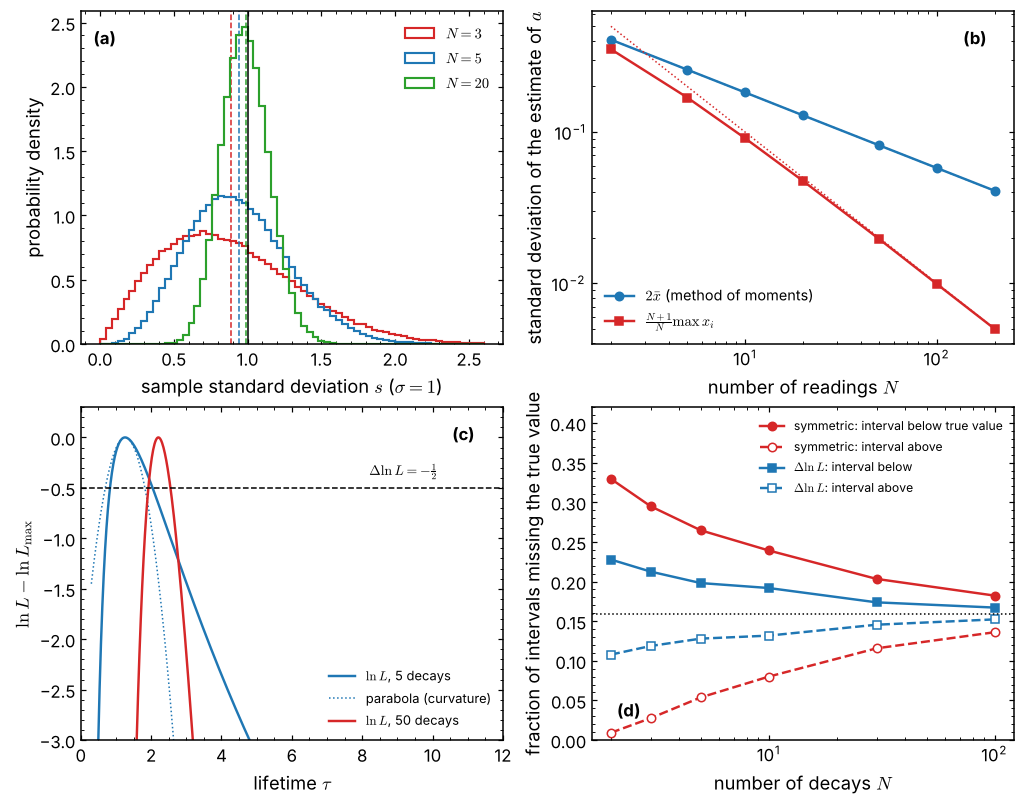

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
bins = np.linspace(0, 2.6, 66)
for N, c in ((3, "C3"), (5, "C0"), (20, "C2")):
    s = rng.normal(0, 1, (200_000, N)).std(axis=1, ddof=1)
    ax.hist(s, bins=bins, density=True, histtype="step", lw=1.4, color=c, label=f"$N={N}$")
    ax.axvline(s.mean(), color=c, ls="--", lw=1)
ax.axvline(1.0, color="k", lw=1)
ax.set_xlabel(r"sample standard deviation $s$ ($\sigma = 1$)"); ax.set_ylabel("probability density")
ax.legend(loc="upper right"); ep.panel_label(ax, "(a)")

ax = axes[0, 1]
ax.loglog(Ns, sd_mm, "o-", color="C0", label=r"$2\bar x$ (method of moments)")
ax.loglog(Ns, sd_max, "s-", color="C3", label=r"$\frac{N+1}{N}\max x_i$")
ax.loglog(Ns, 1 / np.sqrt(3 * Ns), "C0:", lw=1)
ax.loglog(Ns, 1 / Ns, "C3:", lw=1)
ax.set_xlabel("number of readings $N$"); ax.set_ylabel("standard deviation of the estimate of $a$")
ax.legend(loc="lower left"); ep.panel_label(ax, "(b)", x=0.88)

ax = axes[1, 0]
tt = np.linspace(0.3, 12, 600)
ax.plot(tt, lnL(tt, t5) - lnL(tau_hat, t5), "C0", label="$\\ln L$, 5 decays")
ax.plot(tt, -(tt - tau_hat)**2 / (2 * tau_hat**2 / 5), "C0:", lw=1, label="parabola (curvature)")
t50 = rng.exponential(tau_true, 50)
ax.plot(tt, lnL(tt, t50) - lnL(t50.mean(), t50), "C3", label="$\\ln L$, 50 decays")
ax.axhline(-0.5, color="k", ls="--", lw=1)
ax.text(8.2, -0.38, r"$\Delta\ln L = -\frac{1}{2}$", fontsize=9)
ax.set_ylim(-3, 0.3); ax.set_xlim(0, 12)
ax.set_xlabel(r"lifetime $\tau$"); ax.set_ylabel(r"$\ln L - \ln L_\mathrm{max}$")
ax.legend(loc="lower right", fontsize=8.5); ep.panel_label(ax, "(c)", x=0.88)

ax = axes[1, 1]
Nc = [r[0] for r in cov_rows]
ax.semilogx(Nc, [r[1] for r in cov_rows], "o-", color="C3", label="symmetric: interval below true value")
ax.semilogx(Nc, [r[2] for r in cov_rows], "o--", color="C3", mfc="w", label="symmetric: interval above")
ax.semilogx(Nc, [r[3] for r in cov_rows], "s-", color="C0", label=r"$\Delta\ln L$: interval below")
ax.semilogx(Nc, [r[4] for r in cov_rows], "s--", color="C0", mfc="w", label=r"$\Delta\ln L$: interval above")
ax.axhline(0.1587, color="k", ls=":", lw=1)
ax.set_xlabel("number of decays $N$"); ax.set_ylabel("fraction of intervals missing the true value")
ax.set_ylim(0, 0.42); ax.legend(loc="upper right", fontsize=8); ep.panel_label(ax, "(d)", x=0.06, y=0.12)
plt.show()

**(a)** Distribution of the sample standard deviation for $N = 3$, 5 and 20
normal readings with $\sigma = 1$: skewed for small $N$, with its mean
(dashed) below $\sigma$. **(b)** Precision of two unbiased estimators of the
width of a uniform distribution (dotted lines: $1/\sqrt{3N}$ and $1/N$).
**(c)** Log-likelihood of the lifetime for 5 and 50 decays; the
intersections with the dashed line give the likelihood intervals.
**(d)** How often each kind of 68 % interval misses the true lifetime on
either side; ideally 15.9 % each (dotted line).

## Summary

* Judge an estimator by its bias and variance, or by their combination,
  the mean-square error.
* $s^2$ is unbiased for $\sigma^2$; $s$ is low by the factor $c_4(N)$, a
  few per cent for small $N$.
* Natural-looking estimators can be very inefficient; maximum likelihood
  constructs efficient ones systematically.
* The mean, the weighted mean and least squares are all maximum-likelihood
  estimators for normal errors.
* Uncertainties follow from the curvature of $\ln L$ or, for small samples
  and asymmetric cases, from the interval $\Delta\ln L = \tfrac12$.

## References

* G. Cowan, *Statistical Data Analysis* (Oxford University Press, 1998).
* F. James, *Statistical Methods in Experimental Physics*, 2nd ed. (World
  Scientific, 2006).

## Exercises

1. Show that for normal data the mean-square error of $\sum(x_i - \bar x)^2/d$
   is smallest for $d = N+1$.
2. Derive the maximum-likelihood estimate of the mean of a Poisson
   distribution from $n$ counts, and its uncertainty from the curvature.
3. For normally distributed readings with unknown $\mu$ and $\sigma$, find the
   maximum-likelihood estimate of $\sigma^2$. Is it biased?
4. Readings from a uniform distribution on $[\theta, \theta + 1]$ are given.
   Construct an estimator of $\theta$ from the smallest and largest readings
   and compare its precision with that of $\bar x - \tfrac12$.
5. Find the likelihood interval for the decay rate $\lambda = 1/\tau$ from
   the five decays of Section 7.4 and verify that it is the reciprocal of the
   interval for $\tau$. Is the same true of the curvature intervals?

---

**Previous:** [6. Counting statistics](06_counting_statistics.ipynb) &nbsp;·&nbsp; **Next:** [8. Hypothesis tests and goodness of fit](08_hypothesis_tests.ipynb)